<a href="https://colab.research.google.com/github/ckurtz/teaching_UPC_UFRMI/blob/main/selfsupervised_demos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# References

[Course Webpage](https://sites.google.com/view/berkeley-cs294-158-sp20/home)

[1] Pathak, Deepak, et al. "Context encoders: Feature learning by inpainting." Proceedings of the IEEE conference on computer vision and pattern recognition. 2016.

[2] Gidaris, Spyros, Praveer Singh, and Nikos Komodakis. "Unsupervised representation learning by predicting image rotations." arXiv preprint arXiv:1803.07728 (2018).

[3] Chen, Ting, et al. "A simple framework for contrastive learning of visual representations." arXiv preprint arXiv:2002.05709 (2020).

[4] Noroozi, Mehdi, and Paolo Favaro. "Unsupervised learning of visual representations by solving jigsaw puzzles." European Conference on Computer Vision. Springer, Cham, 2016.

[5] Wang, Xiaolong, Allan Jabri, and Alexei A. Efros. "Learning correspondence from the cycle-consistency of time." Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition. 2019.

[6] Oord, Aaron van den, Yazhe Li, and Oriol Vinyals. "Representation learning with contrastive predictive coding." arXiv preprint arXiv:1807.03748 (2018).

[7] Hénaff, Olivier J., et al. "Data-efficient image recognition with contrastive predictive coding." arXiv preprint arXiv:1905.09272 (2019).

[8] Tian, Yonglong, Dilip Krishnan, and Phillip Isola. "Contrastive multiview coding." arXiv preprint arXiv:1906.05849 (2019).

[9] He, Kaiming, et al. "Momentum contrast for unsupervised visual representation learning." arXiv preprint arXiv:1911.05722 (2019).

[10] Doersch, Carl, Abhinav Gupta, and Alexei A. Efros. "Unsupervised visual representation learning by context prediction." Proceedings of the IEEE International Conference on Computer Vision. 2015.

[11] Ronneberger, Olaf, Philipp Fischer, and Thomas Brox. "U-net: Convolutional networks for biomedical image segmentation." International Conference on Medical image computing and computer-assisted intervention. Springer, Cham, 2015.

# Getting Started
Go to **Runtime -> Change runtime type** and make sure **Hardward accelerator** is set to **GPU**

In [3]:
!if [ -d cs294-158-ssl ]; then rm -Rf cs294-158-ssl; fi
!git clone https://github.com/ckurtz/cs294-158-ssl
!pip install cs294-158-ssl/

import os
os.chdir('cs294-158-ssl')

Cloning into 'cs294-158-ssl'...
remote: Enumerating objects: 615, done.
remote: Counting objects: 100% (98/98), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 615 (delta 92), reused 90 (delta 90), pack-reused 517 (from 1)
Receiving objects: 100% (615/615), 3.10 MiB | 31.14 MiB/s, done.
Resolving deltas: 100% (442/442), done.
Processing ./cs294-158-ssl
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for deepul_helper: filename=deepul_helper-0.1.0-py3-none-any.whl size=25330 sha256=2a4daa129cf002e5eac64b45043a115b45d236b9021dc086ad1e9ac811adf75d
  Stored in directory: /tmp/pip-ephem-wheel-cache-xoy5ipt8/wheels/41/c6/8a/07e8f4374eeb04ae58407716e4acc5040e23fe93acd34d166b
Successfully built deepul_helper


Run the cells below to download the necessary pretrained models. It should take a few minutes.

In [4]:
!wget https://camille-kurtz.com/teaching/data.zip
!unzip -qq data.zip
!rm data.zip

--2026-11-01 17:36:40--  https://camille-kurtz.com/teaching/data.zip
Resolving camille-kurtz.com (camille-kurtz.com)... 213.186.33.3
Connecting to camille-kurtz.com (camille-kurtz.com)|213.186.33.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4227668031 (3.9G) [application/zip]
Saving to: ‘data.zip’

data.zip             34%[=====>              ]   1.35G  21.2MB/s    in 81s     

2026-11-01 17:38:02 (17.0 MB/s) - Connection closed at byte 1453249984. Retrying.

--2026-11-01 17:38:03--  (try: 2)  https://camille-kurtz.com/teaching/data.zip
Connecting to camille-kurtz.com (camille-kurtz.com)|213.186.33.3|:443... connected.
HTTP request sent, awaiting response... 206 Partial Content
Length: 4227668031 (3.9G), 2774418047 (2.6G) remaining [application/zip]
Saving to: ‘data.zip’

data.zip            100%[++++++=============>]   3.94G  9.24MB/s    in 6m 51s  

2026-11-01 17:44:55 (6.44 MB/s) - ‘data.zip’ saved [4227668031/4227668031]



In [5]:
!wget https://camille-kurtz.com/teaching/results.zip
!unzip -qq results.zip
!rm results.zip

--2026-11-01 17:45:44--  https://camille-kurtz.com/teaching/results.zip
Resolving camille-kurtz.com (camille-kurtz.com)... 213.186.33.3
Connecting to camille-kurtz.com (camille-kurtz.com)|213.186.33.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2636425194 (2.5G) [application/zip]
Saving to: ‘results.zip’

results.zip         100%[===================>]   2.46G  30.4MB/s    in 97s     

2026-11-01 17:47:23 (25.8 MB/s) - ‘results.zip’ saved [2636425194/2636425194]



The models and demos shown were pre-trained. The code used for all the demos can be found in the github repo [here](https://github.com/wilson1yan/cs294-158-ssl). Follow the README to train models on CIFAR10 or ImageNet.

# Self-Supervised Learning Tasks
Self-supervised learning is a rapidly growing field, its success largely accelerated by growing compute and the vast amount of unlabeled data available for training. The hope is that by pretraining on specially designed self-supervised tasks, the models would be able to learn semantically meaningful representations to be used for downstream tasks. In the following demos, we will look at a few examples of these self-supervised tasks.

In [6]:
from deepul_helper.demos import load_model_and_data, evaluate_accuracy, display_nearest_neighbors, show_context_encoder_inpainting

%matplotlib inline

## Demo 1: Context Encoder [[1]](https://arxiv.org/abs/1604.07379)

The context encoder structures its self-supervised learning task by inpainting masked images. For example, the figure below shows different masking shapes, such as center masking, random block masking, and segmentation masking. Note that segmentation masking (c) is not purely self-supervised since we would need to train a image segmentation model which requires labels. However, the other two masking schemes (a) and (b) and purely self-supervised.

![](https://drive.google.com/uc?id=1fhzkULYTtyMGUUF2n9dlPayJSdcY5pRv)

More formally, the context encoder optimizes the following reconstruction loss:
$$\mathcal{L}_{rec} = \left\Vert \hat{M} \odot (x - F((1 - \hat{M})\odot x)) \right\Vert^2_2$$
where $\hat{M}$ is the masked region, $x$ is the image, and $F$ is the context encoder that tries to reconstruct the masked portion. In addition to the reconstruction loss, the paper introduces an adversarial loss that encourages more realistic inpaintings.
$$L_{adv} = \max_D \mathbb{E}_{x\in \chi} [\log(D(x)) + \log(1 - D(F((1-\hat{M})\odot x)))]$$
However, this demo does not use the adversarial portion of the loss.

### Example Code

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ContextEncoder(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, dataset, n_classes):
        super().__init__()
        input_channels = 3

        self.latent_dim = 4000

        # Encodes the masked image
        self.encoder = nn.Sequential(
            # 128 x 128 Input
            nn.Conv2d(input_channels, 64, 4, stride=2, padding=1), # 64 x 64
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 64, 4, stride=2, padding=1), # 32 x 32
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, stride=2, padding=1), # 16 x 16
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, stride=2, padding=1), # 8 x 8
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 512, 4, stride=2, padding=1), # 4 x 4
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, self.latent_dim, 4) # 1 x 1
        )

        # Only reconstructs the masked part of the image and not the whole image
        self.decoder = nn.Sequential(
           nn.BatchNorm2d(self.latent_dim),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(self.latent_dim, 512, 4, stride=1, padding=0), # 4 x 4
           nn.BatchNorm2d(512),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(512, 256, 4, stride=2, padding=1), # 8 x 8
           nn.BatchNorm2d(256),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), # 16 x 16
           nn.BatchNorm2d(128),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), # 32 x 32
           nn.BatchNorm2d(64),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(64, input_channels, 4, stride=2, padding=1), # 64 x 64
           nn.Tanh()
        )

        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        classifier = nn.Sequential(
            nn.Flatten(),
            nn.BatchNorm1d(self.latent_dim, affine=False),
            nn.Linear(self.latent_dim, self.n_classes)
        )
        return classifier

    def forward(self, images):
        # Extract a 64 x 64 center from 128 x 128 image
        images_center = images[:, :, 32:32+64, 32:32+64].clone()
        images_masked = images.clone()
        # Mask out a 64 x 64 center with slight overlap
        images_masked[:, 0, 32+4:32+64-4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64-4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64-4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0

        z = self.encoder(images_masked)
        center_recon = self.decoder(z)

        return dict(Loss=F.mse_loss(center_recon, images_center)), torch.flatten(z, 1)

    def encode(self, images):
        images_masked = images
        images_masked[:, 0, 32+4:32+64-4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64-4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64-4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0
        return self.encoder(images_masked)

    def reconstruct(self, images):
        images_center = images[:, :, 32:32+64, 32:32+64].clone()
        images_masked = images.clone()
        images_masked[:, 0, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0

        z = self.encoder(images_masked)
        center_recon = self.decoder(z)

        images_recon = images_masked.clone()
        images_recon[:, :, 32:32+64, 32:32+64] = center_recon
        return images_masked, images_recon


### Inpainting Examples
For each pair of images, the left image is the masked input and the right the inpainted reconstruction.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


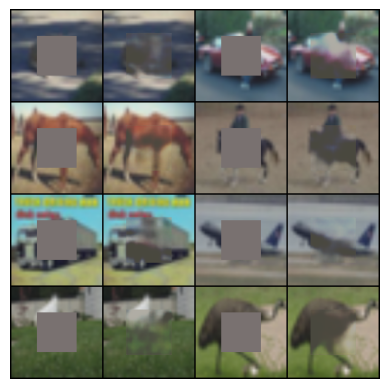

In [8]:
show_context_encoder_inpainting()

### Linear Classification
By design the model architecture is an encoder -> decoder module. We can use the bottleneck layer as our learned representation. Below, we show linear classification accuracy results on CIFAR10 using the learned representations.

In [9]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('context_encoder')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

Train Set
Top 1 Accuracy: 53.236, Top 5 Accuracy: 94.094

Test Set
Top 1 Accuracy: 45.77, Top 5 Accuracy: 90.29



### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


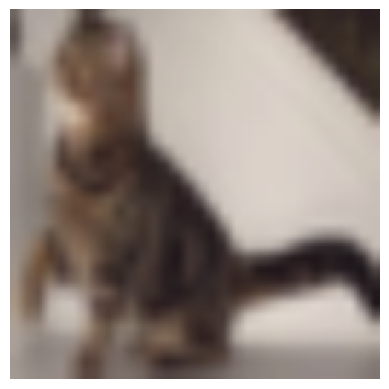

Top 16 Nearest Neighbors (in latent space)


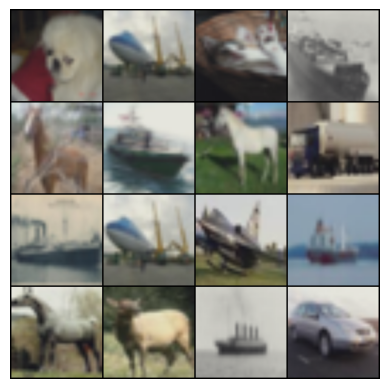

Image 2


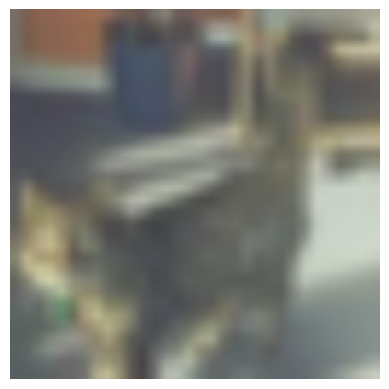

Top 16 Nearest Neighbors (in latent space)


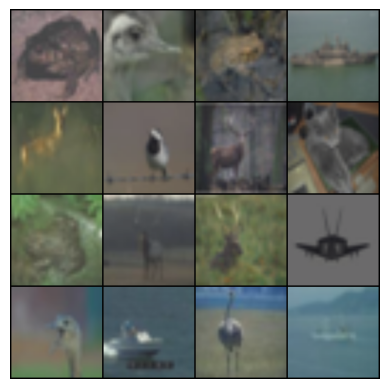

Image 3


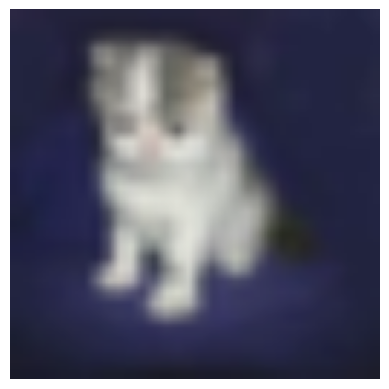

Top 16 Nearest Neighbors (in latent space)


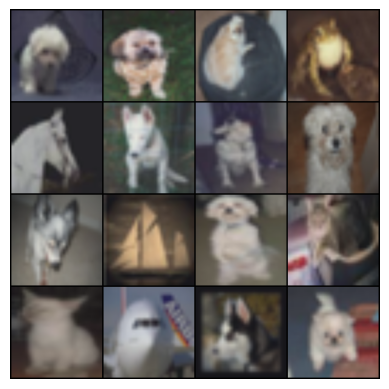

Image 4


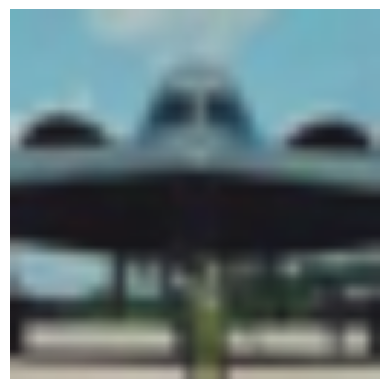

Top 16 Nearest Neighbors (in latent space)


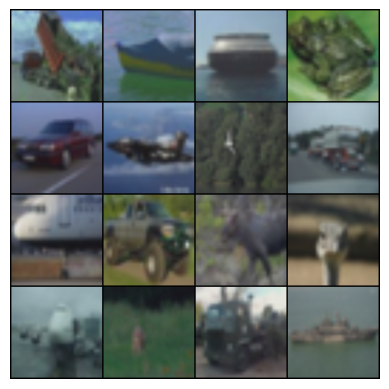

In [10]:
display_nearest_neighbors('context_encoder', model, test_loader)

## Demo 2: Rotation Prediction [[2]](https://arxiv.org/abs/1803.07728)

In this paper, the authors show that accurately predicting the degrees of rotation in images is a self-supervised learning task that learns good representations for downstream tasks.

![](https://drive.google.com/uc?id=1eHXLH-N_6uMGRzdf1Wjnga26qlS5-FRv)

More specifically, the authors showed that training a common CNN architecture (AlexNet, ResNet) on the rotation task learns semantically interpretable convolutional masks similar to those learned in supervised learning.

### Example Code

In [11]:
import math

import torch
import torch.nn as nn
import torch.nn.functional as F


class RotationPrediction(nn.Module):
    metrics = ['Loss', 'Acc1']
    metrics_fmt = [':.4e', ':6.2f']

    def __init__(self, dataset, n_classes):
        super().__init__()
        if dataset == 'cifar10':
            self.model = NetworkInNetwork()
            self.latent_dim = 192 * 8 * 8
            self.feat_layer = 'conv2'
        elif 'imagenet' in dataset:
            self.model = AlexNet()
            self.latent_dim = 256 * 13 * 13
            self.feat_layer = 'conv5'
        else:
            raise Exception('Unsupported dataset:', dataset)
        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        if self.dataset == 'cifar10':
            classifier = nn.Sequential(
                Flatten(),
                nn.BatchNorm1d(self.latent_dim, affine=False),
                nn.Linear(self.latent_dim, self.n_classes)
            )
        elif 'imagenet' in self.dataset:
            classifier = nn.Sequential(
                nn.AdaptiveMaxPool2d((6, 6)),
                nn.BatchNorm2d(256, affine=False),
                Flatten(),
                nn.Linear(256 * 6 * 6, self.n_classes)
            )
        else:
            raise Exception('Unsupported dataset:', dataset)
        return classifier

    def forward(self, images):
        batch_size = images.shape[0]
        images, targets = self._preprocess(images)
        targets = targets.to(images.get_device())

        logits, zs = self.model(images, out_feat_keys=('classifier', self.feat_layer))
        loss = F.cross_entropy(logits, targets)

        pred = logits.argmax(dim=-1)
        correct = pred.eq(targets).float().sum()
        acc = correct / targets.shape[0] * 100.

        return dict(Loss=loss, Acc1=acc), zs[:batch_size]

    def encode(self, images):
        zs = self.model(images, out_feat_keys=(self.feat_layer,))
        return zs

    def _preprocess(self, images):
        batch_size = images.shape[0]
        images_90 = torch.flip(images.transpose(2, 3), (2,))
        images_180 = torch.flip(images, (2, 3))
        images_270 = torch.flip(images, (2,)).transpose(2, 3)
        images_batch = torch.cat((images, images_90, images_180, images_270), dim=0)
        targets = torch.arange(4).long().repeat(batch_size)
        targets = targets.view(batch_size, 4).transpose(0, 1)
        targets = targets.contiguous().view(-1)
        return images_batch, targets

### Linear Classification
We can use the feature maps in the later convolutional layers of the pretrained model as our learned representation for linear classification.

In [12]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('rotation')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

Train Set
Top 1 Accuracy: 79.428, Top 5 Accuracy: 99.102

Test Set
Top 1 Accuracy: 79.91, Top 5 Accuracy: 99.12



### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


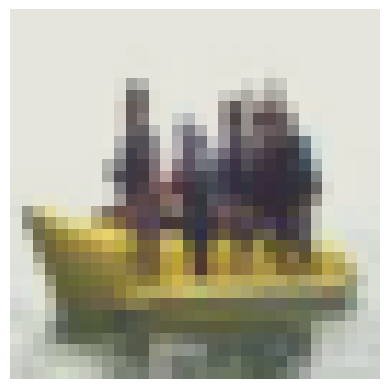

Top 16 Nearest Neighbors (in latent space)


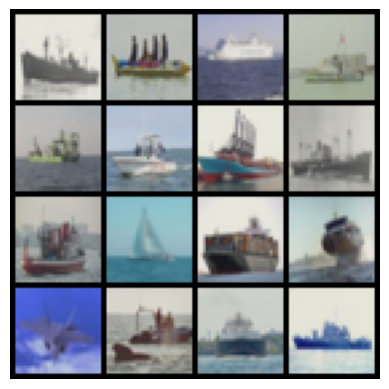

Image 2


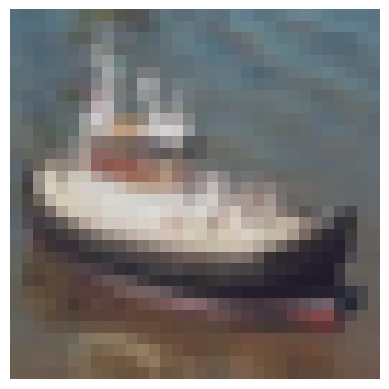

Top 16 Nearest Neighbors (in latent space)


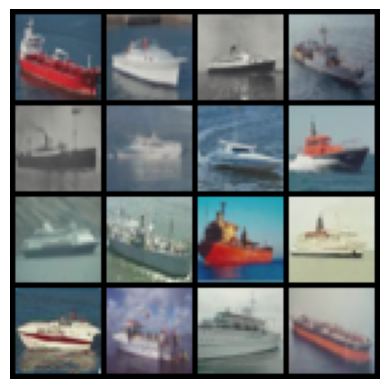

Image 3


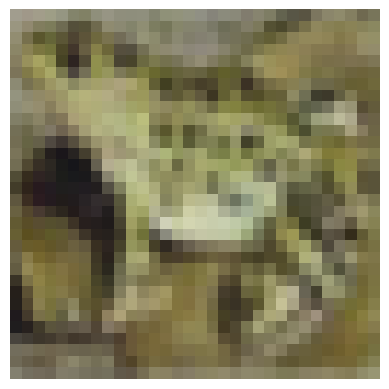

Top 16 Nearest Neighbors (in latent space)


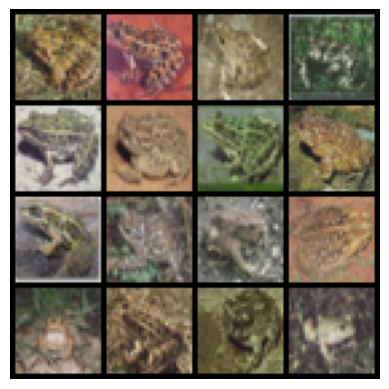

Image 4


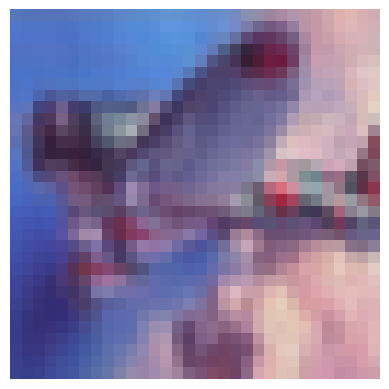

Top 16 Nearest Neighbors (in latent space)


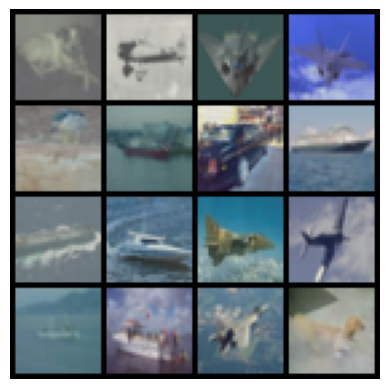

In [13]:
display_nearest_neighbors('rotation', model, test_loader)

## Demo 3: SimCLR [[3]](https://arxiv.org/abs/2002.05709)

SimCLR is a contrastive learning framework to learn strong visual representations. An image $x$ is processed using data augmentation to produce two variants $x_i$ and $x_j$ which are both fed into encoder $f$ (a CNN) and projection head $g$ (a small MLP). The models optimize a contrastive loss to maximally align projected latents $z_i, z_j$. We consider $x_i, x_j$ as a positive pair, and any other $x_i, x_k$ pairs (i.e. different images in the same batch) are negative pairs. A visual diagram of the training procedure is shown below (from the paper).

![](https://drive.google.com/uc?id=1XW1uIkUTMSa0DZncivSYXzM5gA5FIhF6)

More formally, the loss between positive example $z_i, z_j$ is:
$$\ell_{i,j} = -\log{\frac{\exp(\text{sim}(z_i, z_j)/\tau)}{\sum_{k=1}^{2N}\mathbb{1}_{[k\neq i]}\exp(\text{sim}(z_i, z_k)/\tau)}}$$
where $\text{sim}(z_i, z_j) = z_i^Tz_j / (\left\Vert z_i \right\Vert \left\Vert z_j \right\Vert)$. The loss function can also be interpreted as a standard cross entropy loss to classify positive samples where logits are constructed using a given similarity function.

Note: A common idea in contrastive learning methods is that a larger batch means more negative samples. Therefore, these methods usually benefit the most from large-batch learning compared to other self-supervised learning tasks.

### Example Code

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from deepul_helper.resnet import resnet_v1
from deepul_helper.batch_norm import SyncBatchNorm, BatchNorm1d

# Some code adapted from https://github.com/sthalles/SimCLR
class SimCLR(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, dataset, n_classes, dist=None):
        super().__init__()
        self.temperature = 0.5
        self.projection_dim = 128

        if dataset == 'cifar10':
            resnet = resnet_v1((3, 32, 32), 50, 1, cifar_stem=True)
            resnet = SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.resnet = resnet
            self.latent_dim = 2048
        elif 'imagenet' in dataset:
            resnet = resnet_v1((3, 128, 128), 50, 1, cifar_stem=False)
            if dist is not None:
                resnet = nn.SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.resnet = resnet
            self.latent_dim = 2048

        self.proj = nn.Sequential(
            nn.Linear(self.latent_dim, self.projection_dim, bias=False),
            BatchNorm1d(self.projection_dim),
            nn.ReLU(inplace=True),
            nn.Linear(self.projection_dim, self.projection_dim, bias=False),
            BatchNorm1d(self.projection_dim, center=False)
        )

        self.dataset = dataset
        self.n_classes = n_classes
        self.dist = dist

    def construct_classifier(self):
        return nn.Sequential(nn.Linear(self.latent_dim, self.n_classes))

    def forward(self, images):
        n = images[0].shape[0]
        xi, xj = images
        hi, hj = self.encode(xi), self.encode(xj) # (N, latent_dim)
        zi, zj = self.proj(hi), self.proj(hj) # (N, projection_dim)
        zi, zj = F.normalize(zi), F.normalize(zj)

        # Each training example has 2N - 2 negative samples
        # 2N total samples, but exclude the current and positive sample

        if self.dist is None:
            zis = [zi]
            zjs = [zj]
        else:
            zis = [torch.zeros_like(zi) for _ in range(self.dist.get_world_size())]
            zjs = [torch.zeros_like(zj) for _ in range(self.dist.get_world_size())]

            self.dist.all_gather(zis, zi)
            self.dist.all_gather(zjs, zj)

        z1 = torch.cat((zi, zj), dim=0) # (2N, projection_dim)
        z2 = torch.cat(zis + zjs, dim=0) # (2N * n_gpus, projection_dim)

        sim_matrix = torch.mm(z1, z2.t()) # (2N, 2N * n_gpus)
        sim_matrix = sim_matrix / self.temperature
        # Mask out same-sample terms
        n_gpus = 1 if self.dist is None else self.dist.get_world_size()
        rank = 0 if self.dist is None else self.dist.get_rank()
        sim_matrix[torch.arange(n), torch.arange(rank*n, (rank+1)*n)]  = -float('inf')
        sim_matrix[torch.arange(n, 2*n), torch.arange((n_gpus+rank)*n, (n_gpus+rank+1)*n)] = -float('inf')

        targets = torch.cat((torch.arange((n_gpus+rank)*n, (n_gpus+rank+1)*n),
                             torch.arange(rank*n, (rank+1)*n)), dim=0)
        targets = targets.to(sim_matrix.get_device()).long()

        loss = F.cross_entropy(sim_matrix, targets, reduction='sum')
        loss = loss / n
        return dict(Loss=loss), hi

    def encode(self, images):
        return self.resnet(images[0])

    def get_features(self, images):
        return self.resnet.get_features(images)


### Linear Classification
We can use the encoded vector $h_i$ as our latent representation.

In [15]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('simclr')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

Train Set
Top 1 Accuracy: 90.218, Top 5 Accuracy: 99.478

Test Set
Top 1 Accuracy: 92.84, Top 5 Accuracy: 99.86



### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


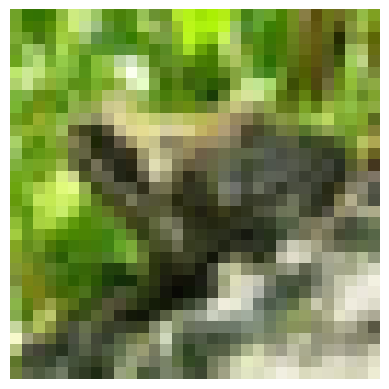

Top 16 Nearest Neighbors (in latent space)


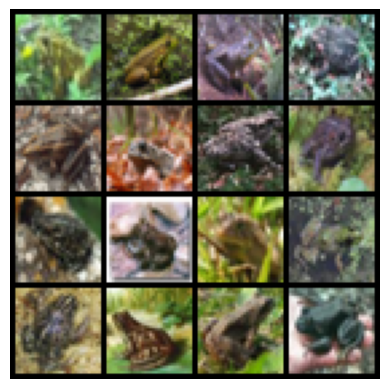

Image 2


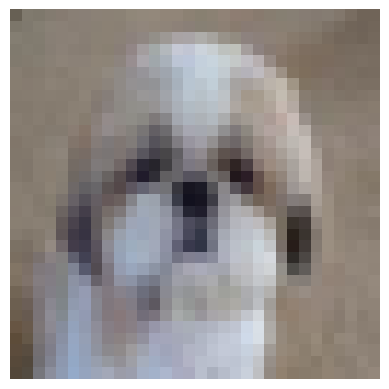

Top 16 Nearest Neighbors (in latent space)


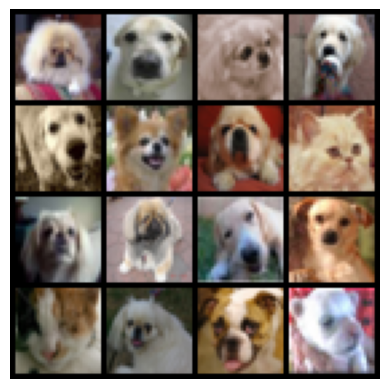

Image 3


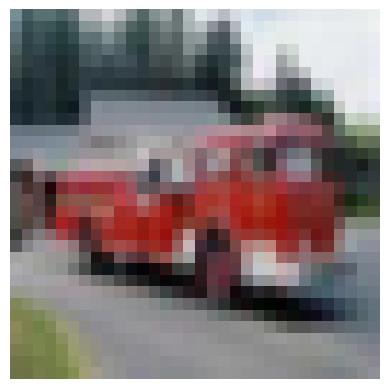

Top 16 Nearest Neighbors (in latent space)


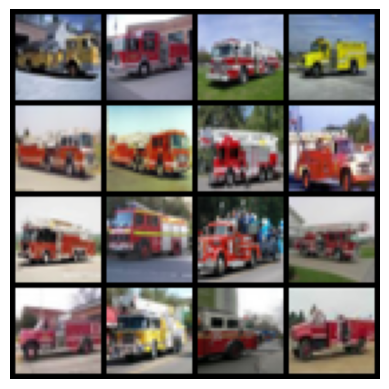

Image 4


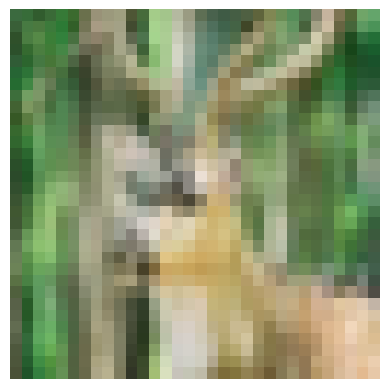

Top 16 Nearest Neighbors (in latent space)


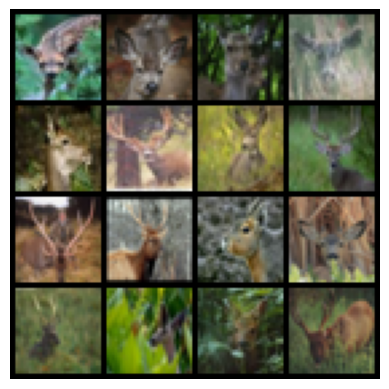

In [16]:
display_nearest_neighbors('simclr', model, test_loader)

In [17]:
import inspect
print(inspect.getsource(evaluate_accuracy))


def evaluate_accuracy(model, linear_classifier, train_loader, test_loader):
    train_acc1, train_acc5 = evaluate_classifier(model, linear_classifier, train_loader)
    test_acc1, test_acc5 = evaluate_classifier(model, linear_classifier, test_loader)

    print('Train Set')
    print(f'Top 1 Accuracy: {train_acc1}, Top 5 Accuracy: {train_acc5}\n')
    print('Test Set')
    print(f'Top 1 Accuracy: {test_acc1}, Top 5 Accuracy: {test_acc5}\n')



In [18]:
from deepul_helper.demos import evaluate_classifier
import inspect
print(inspect.getsource(evaluate_classifier))

def evaluate_classifier(model, linear_classifier, loader):
    correct1, correct5 = 0, 0
    with torch.no_grad():
        for images, target in loader:
            images = images_to_cuda(images)
            target = target.cuda(non_blocking=True)
            out, zs = model(images)

            logits = linear_classifier(zs)
            acc1, acc5 = accuracy(logits, target, topk=(1, 5))

            correct1 += acc1.item() * logits.shape[0]
            correct5 += acc5.item() * logits.shape[0]
    total = len(loader.dataset)

    return correct1 / total, correct5 / total



# Faire la comparaison des resultats des trois methode

In [19]:
def obtenir_prediction(model, linear_classifier, loader):
  y_test = []
  y_pred = []

  model.eval()
  linear_classifier.eval()

  with torch.inference_mode():
    for image, target in loader:
      images = images_to_cuda(image)
      target = target.cuda(non_blocking=True)
      out, zs = model(images)
      logits = linear_classifier(zs)
      predictions = torch.argmax(logits, dim=1)

      y_test.append(target.cpu())
      y_pred.append(predictions.cpu())

  y_test = torch.cat(y_test).numpy()
  y_pred = torch.cat(y_pred).numpy()

  return y_test, y_pred

In [20]:
from deepul_helper.demos import images_to_cuda
resultats = {}
for nom in ['context_encoder', 'rotation', 'simclr']:
  model, linear_classifier, _, test_loader = load_model_and_data(nom)
  y_test, y_pred = obtenir_prediction(model, linear_classifier, test_loader)
  resultats[nom] = (y_test, y_pred)
print(resultats)

{'context_encoder': (array([5, 1, 3, ..., 3, 0, 8]), array([2, 1, 3, ..., 3, 8, 8])), 'rotation': (array([2, 3, 0, ..., 8, 9, 3]), array([2, 3, 0, ..., 8, 9, 3])), 'simclr': (array([9, 4, 2, ..., 4, 3, 4]), array([9, 4, 2, ..., 4, 3, 4]))}


In [21]:
print(len(resultats['context_encoder'][0]))

10000


In [22]:
def affichage_comparaison(resultats):
  noms = []
  accuracies = []

  for nom in resultats.keys():
    y_test, y_pred = resultats[nom]
    accuracy = (np.sum(y_test == y_pred) / len(y_test)) * 100
    noms.append(nom)
    accuracies.append(accuracy)

  plt.bar(noms, accuracies)
  plt.ylabel("Accuracy (%)")
  plt.title("Comparaison des méthodes ")
  plt.show()


In [23]:
affichage_comparaison(resultats)

NameError: name 'np' is not defined

Matrice de confusion

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# recuperer les classes du dataset
classes = test_loader.dataset.classes

# recuperer les données
y_test, y_pred = resultats["rotation"]

matrice_conf = confusion_matrix(y_test, y_pred)

# affichage de la matrice
affichage = ConfusionMatrixDisplay(matrice_conf, display_labels=classes)
affichage.plot(xticks_rotation=45)
plt.title("Matrice de confusion")
plt.show()
# on peut faie une methode pour ne pas avoir de probleme

# Comparaison sur un autre jeu de données CIFAR-100 (qui contient 100 classes avec le meme nombre d'image d'entrainement et de test)

In [48]:
import numpy as np
from torchvision import datasets
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader, Subset
from deepul_helper.demos import load_model_and_data, images_to_cuda
from deepul_helper.data import get_transform
from deepul_helper.utils import accuracy


def get_loader(task, train, nbr_max = None):
  # charger le jeu de donnés CIFAR-100
  # pretraitement
  data_transform = get_transform("cifar10", task, train = False)
  data = datasets.CIFAR100('data/cifar100', train = train, transform = data_transform, download = True)# telecharger les image de CIFAR-100

  # si on veut juste prendre une partie des images
  if nbr_max:
    idx = torch.randperm(len(data), generator = torch.Generator().manual_seed(0))[:nbr_max]
    data = Subset(data, idx.tolist())

  return DataLoader(data, batch_size = 128, shuffle = False, num_workers=2) # num_workers : nbr processus qui prepare les images

@torch.inference_mode()
def extraction(model, loader):
  vect_repres = []
  true_labels = []
  for image, target in loader:
    _, zs = model(images_to_cuda(image)) # mettre les image dans le gpu
    vect_repres.append(zs.half().cpu())
    true_labels.append(target)

  return torch.cat(vect_repres), torch.cat(true_labels) # regroupe toutes les données




In [66]:
# evalutation du model

def evaluation(task, epochs = 100, model = None):
  # chargement du model
  if model is None:
    model, _, _, _ = load_model_and_data(task)

  model.eval()
  # extraction des representation
  X_train, y_train = extraction(model, get_loader(task, True, nbr_max=30000))
  x_test, y_test = extraction(model, get_loader(task, False))

  # nouveau classifieur avec 100 sorties
  model.n_classes = 100
  classifieur = model.construct_classifier().cuda()
  optimizer = torch.optim.Adam(classifieur.parameters(), lr = 0.01)

  # mettre les données dans le gpu
  X_train = X_train.cuda()
  y_train = y_train.cuda()

  for epoch in range(epochs):
    classifieur.train()

    for indice_imgs in torch.randperm(len(X_train), device = "cuda").split(256):
      loss = F.cross_entropy(classifieur(X_train[indice_imgs].float()), y_train[indice_imgs])
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

  classifieur.eval()
  with torch.inference_mode():
    logits = classifieur(x_test.cuda().float())

  top1_acc, top5_acc = accuracy(logits, y_test.cuda(), topk = (1, 5))
  print(f"{task} : top1 accurcy = {top1_acc.item():.2f}% et la top5 accuracy = {top5_acc.item():.2f}%")

  y_pred = logits.argmax(dim=1).cpu().numpy() # classe predite
  return y_test.numpy(), y_pred

context_encoder : top1 accurcy = 19.14% et la top5 accuracy = 42.32%
rotation : top1 accurcy = 47.31% et la top5 accuracy = 74.42%
simclr : top1 accurcy = 55.04% et la top5 accuracy = 83.36%


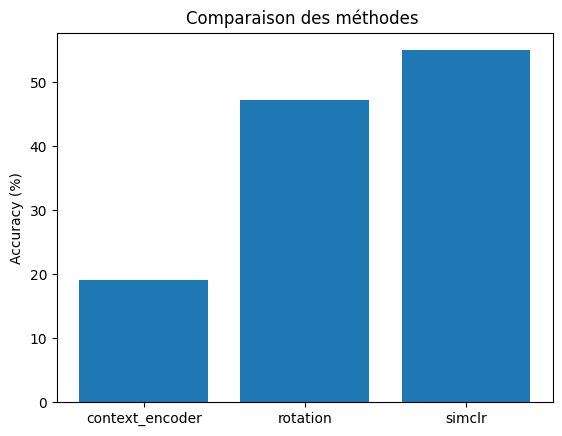

In [55]:
resultats_cifar100 = {}
for nom in ['context_encoder', 'rotation', 'simclr']:
    resultats_cifar100[nom] = evaluation(nom)

affichage_comparaison(resultats_cifar100)

In [56]:
"""classes = datasets.CIFAR100('data/cifar100', train=False).classes   # recuperer le nom des classe
y_test, y_pred = resultats_cifar100["simclr"]
matrice_conf = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
affichage = ConfusionMatrixDisplay(matrice_conf)
affichage.plot(ax=ax, include_values=False, colorbar=True)
ax.set_xticks([]); ax.set_yticks([])
plt.title("Matrice de confusion CIFAR-100")
plt.show()""" # matrice de confusion beacoup trop grande

'classes = datasets.CIFAR100(\'data/cifar100\', train=False).classes   # recuperer le nom des classe\ny_test, y_pred = resultats_cifar100["simclr"]\nmatrice_conf = confusion_matrix(y_test, y_pred)\n\nfig, ax = plt.subplots(figsize=(10, 10))\naffichage = ConfusionMatrixDisplay(matrice_conf)\naffichage.plot(ax=ax, include_values=False, colorbar=True)   \nax.set_xticks([]); ax.set_yticks([])           \nplt.title("Matrice de confusion CIFAR-100")\nplt.show()'

# reconnaissance de la position d'un voisin

In [57]:
# positions voisins
VOISINS = [(-1, -1), (-1, 0), (-1, 1),
           ( 0, -1),          ( 0, 1),
           ( 1, -1), ( 1, 0), ( 1, 1)]

# label des classes voisine
CLASSES = ['haut_gauche', 'haut_centre', 'haut_droite',
           'gauche','droite',
           'bas_gauche', 'bas_centre', 'bas_droite']

# praitraitement sur images
# on commence par aggrandire les images, sinon les patch vont etres tres petit
TAILLE_IMG   = 64
TAILLE_CASE  = 21
TAILLE_PATCH = 16
SLIDE = 2

# renvoie le coin des patch
def coin_patch(ligne, colonne):
    r = ligne * TAILLE_CASE + torch.randint(0, SLIDE + 1, (1,)).item()     # début de la case + décalage aléatoire vertical
    c = colonne * TAILLE_CASE + torch.randint(0, SLIDE + 1, (1,)).item()   # début de la case + décalage aléatoire horizontal
    return r, c

# suppression des indice qui peuvent aider le modele ainsi ameliorer la qualité d'entrainement
def anti_triche(patch, train=True):
    if train and torch.rand(1).item() < 0.5:
        patch = patch.mean(0, keepdim=True).repeat(3, 1, 1)
    return patch - patch.mean(dim=(1, 2), keepdim=True)

In [61]:
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
#Dataset qui renvoie, pour chaque image CIFAR-10 : (patch central, patch voisin, position du voisin)."""

class Paires_Patchs(Dataset):
    def __init__(self, train):
        # On charge CIFAR-10 au format PIL, sans transformation pour l'instant
        self.images = datasets.CIFAR10('data/cifar10', train=train, download=True)
        self.train = train

        # Prétraitement appliqué à chaque image avant de découper les patchs
        self.pretraitement = transforms.Compose([
            transforms.Resize(TAILLE_IMG),                   # 32x32 -> 64x64
            transforms.ToTensor(),                           # image PIL -> tenseur 3x64x64 avec des valeurs entre 0 et 1
            transforms.Normalize((0.4914, 0.4822, 0.4465),
                                 (0.247, 0.243, 0.261))])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img, _ = self.images[i]
        x = self.pretraitement(img)

        position = torch.randint(0, 8, (1,)).item()
        dl, dc = VOISINS[position]

        r1, c1 = coin_patch(1, 1)
        r2, c2 = coin_patch(1 + dl, 1 + dc)

        # Découpage : x[canaux, lignes, colonnes] on garde tous les canaux et un carré de 16x16
        centre = x[:, r1:r1 + TAILLE_PATCH, c1:c1 + TAILLE_PATCH]
        voisin = x[:, r2:r2 + TAILLE_PATCH, c2:c2 + TAILLE_PATCH]

        # On applique les protections anti-triche aux deux patchs, puis on renvoie la paire et le label
        return anti_triche(centre, self.train), anti_triche(voisin, self.train), position

In [62]:

def architecture_model(entree, sortie):
    #convolution 3x3 + normalisation  + activation relu
    return [nn.Conv2d(entree, sortie, kernel_size=3, padding=1, bias=False),  # padding=1, la taille de l'image ne change pas
            nn.BatchNorm2d(sortie),                                           # stabilise et accélère l'entraînement
            nn.ReLU(inplace=True)]                                            # non-linéarité : max(0, x)


class PositionRelative(nn.Module):
    def __init__(self):
        super().__init__()                                   # initialisation obligatoire d'un nn.Module
        self.n_classes = 10                                  # nombre de classes du classifieur linéaire (changé en 100 par evaluation)

        # encoder des deux patchs
        self.encodeur = nn.Sequential(
            *architecture_model(3, 64),
            *architecture_model(64, 64),
            nn.MaxPool2d(2),
            *architecture_model(64, 128),
            *architecture_model(128, 128),
            nn.MaxPool2d(2),
            *architecture_model(128, 256),
            *architecture_model(256, 256))


        # Vecteur patch
        self.fc_patch = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True))

        # decider la position du patch
        self.tete = nn.Sequential(
            nn.Linear(2 * 512, 512),  # les 2 vecteurs collés (1024)
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 8))        # 8 scores, un par position

    def predire_position(self, centre, voisin):

        f_centre = self.fc_patch(self.encodeur(centre))      # vecteur du patch central (batch x 512)
        f_voisin = self.fc_patch(self.encodeur(voisin))      # vecteur du patch voisin, avec le MÊME encodeur (siamois)
        f = torch.cat([f_centre, f_voisin], dim=1)           # on colle les deux vecteurs côte à côte (batch x 1024)
        return self.tete(f)                                  # 8 scores par paire (batch x 8)

    def forward(self, images):

        x = F.interpolate(images, size=TAILLE_IMG, mode='bilinear', align_corners=False)   # 32x32 -> 64x64 (même échelle qu'à l'entraînement)
        x = x - x.mean(dim=(2, 3), keepdim=True)             # même soustraction de la moyenne qu'à l'entraînement
        carte = self.encodeur(x)                             # l'encodeur sur l'image entière : carte de taille 256 x 16 x 16
        zs = F.adaptive_avg_pool2d(carte, 4)                 # moyenne par zones -> 256 x 4 x 4
        zs = zs.flatten(1)                                   # -> vecteur de 4096 nombres = la représentation
        return None, zs                                      # (pas de perte, représentation) comme "out, zs = model(images)" chez le prof

    def construct_classifier(self):
        return nn.Sequential(nn.BatchNorm1d(256 * 4 * 4, affine=False),
                             nn.Linear(256 * 4 * 4, self.n_classes))

# entrainement du modele

In [72]:
EPOCHS = 30

# Chargement des paires par paquets
train_loader = DataLoader(Paires_Patchs(train=True),           # paires d'entraînement
                          batch_size=256,                      # 256 paires par paquet
                          shuffle=True,                        # ordre mélangé à chaque époque
                          num_workers=2,                       # 2 processus préparent les paires en parallèle
                          drop_last=True)                      # on jette le dernier paquet incomplet (évite un souci avec BatchNorm)
test_loader  = DataLoader(Paires_Patchs(train=False),          # paires de test
                          batch_size=256, shuffle=False, num_workers=2)

# Modèle et optimiseur
modele_patch = PositionRelative().cuda()                           # on crée le modèle et on le met sur le GPU
optimizer = torch.optim.Adam(modele_patch.parameters(), lr=0.005)
historique = []                                                    # pour garder (loss, acc train, acc test) de chaque époque

for epoch in range(EPOCHS):

    modele_patch.train()
    somme_loss, bonnes, total = 0, 0, 0
    for centre, voisin, position in train_loader:              # un paquet de 256 paires
        centre = centre.cuda()                                 # on envoie les données sur le GPU
        voisin = voisin.cuda()
        position = position.cuda()

        logits = modele_patch.predire_position(centre, voisin) # 8 scores par paire
        loss = F.cross_entropy(logits, position)               # erreur entre les scores et la vraie position

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        somme_loss += loss.item() * len(position)
        bonnes += (logits.argmax(1) == position).sum().item()  # position prédite
        total += len(position)                                 # nombre de paires vues

    # test
    modele_patch.eval()
    bonnes_test, total_test = 0, 0
    with torch.inference_mode():
        for centre, voisin, position in test_loader:
            logits = modele_patch.predire_position(centre.cuda(), voisin.cuda())
            bonnes_test += (logits.argmax(1).cpu() == position).sum().item()
            total_test += len(position)

    acc_train = 100 * bonnes / total
    acc_test = 100 * bonnes_test / total_test
    historique.append((somme_loss / total, acc_train, acc_test))
    print(f"Époque {epoch+1:2d}/{EPOCHS} | loss {somme_loss/total:.4f} | "
          f"acc train {acc_train:.2f}% | acc test {acc_test:.2f}%")

torch.save(modele_patch.state_dict(), 'modele_patch.pth')

Époque  1/30 | loss 1.9965 | acc train 21.76% | acc test 28.63%
Époque  2/30 | loss 1.8216 | acc train 30.15% | acc test 31.49%
Époque  3/30 | loss 1.7349 | acc train 34.14% | acc test 34.37%
Époque  4/30 | loss 1.6685 | acc train 37.00% | acc test 36.42%
Époque  5/30 | loss 1.6007 | acc train 40.07% | acc test 41.33%
Époque  6/30 | loss 1.5164 | acc train 43.41% | acc test 43.36%
Époque  7/30 | loss 1.4605 | acc train 45.82% | acc test 44.19%
Époque  8/30 | loss 1.4170 | acc train 47.41% | acc test 44.82%
Époque  9/30 | loss 1.3767 | acc train 48.96% | acc test 49.11%
Époque 10/30 | loss 1.3448 | acc train 50.20% | acc test 46.27%
Époque 11/30 | loss 1.3296 | acc train 50.54% | acc test 49.35%
Époque 12/30 | loss 1.3030 | acc train 51.66% | acc test 50.42%
Époque 13/30 | loss 1.2838 | acc train 52.35% | acc test 49.83%
Époque 14/30 | loss 1.2634 | acc train 53.35% | acc test 51.36%
Époque 15/30 | loss 1.2529 | acc train 53.76% | acc test 47.67%
Époque 16/30 | loss 1.2397 | acc train 5

rotation : top1 accurcy = 33.29% et la top5 accuracy = 60.23%


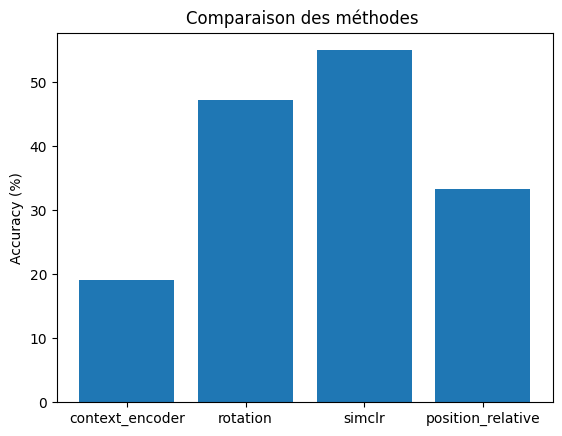

In [73]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

resultats_cifar100['position_relative'] = evaluation('rotation', model=modele_patch)

# 2) Même graphique que la Q3 / Q4, maintenant avec les 4 modèles
affichage_comparaison(resultats_cifar100)